In [2]:
# Setup project imports
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

%load_ext autoreload
%autoreload 2

Project root: e:\Automation_IT\3\Drift case study\MAIT_G2_Drift_Challenge


In [3]:
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
import contextlib
import plotly.graph_objects as go

from utils.reproducibility_utils import seed_everything
from utils.data_loadingV2 import load_data, load_test_data, feature_names
from utils.LDS_FocalR_Loss import EnhancedLDS_FocalR_Loss
from utils.SimpleBucketLoss import SimpleBucketLoss
from utils.kaggle_metric import score
from models.gru import GRUModel

plt.style.use('seaborn-v0_8')

In [4]:
CONFIG = {
    # Paths
    'TRAIN_PATH': "../datasets_challenge/train",
    'TEST_PATH': "../datasets_challenge/test",
    'DIST_CSV': "../datasets_challenge/sideSlip_distribution.csv",
    'CHECKPOINT_NAME': "best_modelv8.pth", 
    'SUBMISSION_CSV': "predictionsv8.csv",  
    
    # Reproducibility
    'SEED': 42,
    
    # Data Loading
    'TRAIN_RATIO': 0.8,
    'BATCH_SIZE': 512,
    'SEQUENCE_LENGTH': 20, 
    'THRESHOLD': True,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': "vxCG",
    'COLUMNS_TO_DROP': ["sideSlip", "vyCG", "time", "longitude", "latitude"],
    'TARGET': "sideSlip",
    'SCALING': True,
    
    # Model Architecture - GRU
    'MODEL_TYPE': 'GRU',  
    'RNN_UNITS': 128,
    'FC_UNITS': 128,
    'NUM_LAYERS': 2,
    'DROPOUT': [0.25, 0.15, 0.1],
    'USE_BATCH_NORM': True,  
    
    # Loss Configuration - 🔥 BALANCED WEIGHTS (Fix #2)
    'LOSS_TYPE': 'EnhancedLDS_FocalR_Loss',
    'LOSS_WEIGHTS': (1.0, 1.0, 1.0),  
    'USE_HUBER': True,
    'HUBER_BETA': 0.07,
    'LDS_SIGMA': 2.0,
    'FOCAL_GAMMA': 1.0,
    'BINS': 100,
    'USE_COMBINED_DISTRIBUTION': False,
    
    # Optimizer
    'LEARNING_RATE': 5e-4,
    'WEIGHT_DECAY': 6e-4,
    'BETAS': (0.9, 0.999),
    'MAX_GRAD_NORM': 1.0,
    
    # Scheduler
    'USE_SCHEDULER': True,
    'SCHEDULER_T_MAX': 400,
    'SCHEDULER_ETA_MIN': 1e-5,
    
    # Training
    'NUM_EPOCHS': 400,
    'EARLY_STOP_PATIENCE': 400,
    'USE_AMP': True,
    
    # Challenge Constraints -
    'MANY_SHOT_CONSTRAINT': 0.2,       
    'MANY_SHOT_SAFETY_MARGIN': 0.19,   
    'FEW_SHOT_TARGET': 0.35,
    
    # Visualization
    'FIG_SIZE': (14, 8),
    'PLOTLY_WIDTH': 1200,
    'PLOTLY_HEIGHT': 500,
}

In [5]:
seed_everything(CONFIG['SEED'])
print(f"Random seed set to {CONFIG['SEED']}")

Random seed set to 42


## Load Data

In [7]:
train_dataloader, val_dataloader, pipeline, mean_dict, std_dict = load_data(
    train_path=CONFIG['TRAIN_PATH'],
    train_ratio=CONFIG['TRAIN_RATIO'],
    batchsize=CONFIG['BATCH_SIZE'],
    columns_to_standardize=feature_names,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    scaling=CONFIG['SCALING'],
    seed=CONFIG['SEED'],
    shuffle=True
)

../datasets_challenge/train\train_part_001.csv
../datasets_challenge/train\train_part_002.csv
../datasets_challenge/train\train_part_003.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\train_part_012.csv
../datasets_challenge/train\train_part_013.csv
../datasets_challenge/train\train_part_014.csv
../datasets_challenge/train\train_part_015.csv
../datasets_challenge/train\train_part_016.csv
../datasets_challenge/train\train_part_017.csv
../datasets_challenge/train\train_part_018.csv
../datasets_challenge/train\train_part_019.csv
../datasets_challenge/train\train_part_020.csv
../datasets_challenge/train\train_part_021.csv
../datasets_c

In [6]:
# Extract training targets for loss function
all_train_targets = []
for i in range(len(train_dataloader.dataset)):
    _, y = train_dataloader.dataset[i]
    all_train_targets.append(y.item())

y_train_np = np.array(all_train_targets)
print(f"Training samples: {len(y_train_np):,}")


Training samples: 104,070


## Setup Model & Training

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# AMP setup
if torch.cuda.is_available():
    amp_device_type = "cuda"
    amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    scaler = torch.amp.GradScaler(amp_device_type, enabled=CONFIG['USE_AMP'])
else:
    amp_device_type = None
    amp_dtype = None
    scaler = torch.amp.GradScaler("cuda", enabled=False)

def autocast_ctx():
    if amp_device_type is None or not CONFIG['USE_AMP']:
        return contextlib.nullcontext()
    return torch.amp.autocast(device_type=amp_device_type, dtype=amp_dtype, enabled=True)

# Get input size
X_sample, _ = next(iter(train_dataloader))
input_size = X_sample.shape[2]
seq_length = X_sample.shape[1]

print(f"\n📊 Input shape: (batch={X_sample.shape[0]}, seq={seq_length}, features={input_size})")

# Create GRU model
model = GRUModel(
    input_size=input_size,
    output_size=1,
    rnn_units=CONFIG['RNN_UNITS'],
    fc_units=CONFIG['FC_UNITS'],
    dropout=CONFIG['DROPOUT'],
    num_layers=CONFIG['NUM_LAYERS'],
    use_batch_norm=CONFIG['USE_BATCH_NORM']
).to(device)

# Create loss function
if CONFIG['LOSS_TYPE'] == 'SimpleBucket':
    criterion = SimpleBucketLoss(
        train_targets=y_train_np,
        bucket_weights=CONFIG['LOSS_WEIGHTS'],
        use_huber=CONFIG['USE_HUBER'],
        huber_beta=CONFIG['HUBER_BETA'],
        dist_csv_path=CONFIG['DIST_CSV']
    ).to(device)
else:
    criterion = EnhancedLDS_FocalR_Loss(
        train_targets=y_train_np,
        bucket_weights=CONFIG['LOSS_WEIGHTS'],
        lds_kernel='gaussian',
        lds_ks=CONFIG['LDS_SIGMA'],
        lds_sigma=CONFIG['LDS_SIGMA'],
        focal_gamma=CONFIG['FOCAL_GAMMA'],
        use_huber=CONFIG['USE_HUBER'],
        huber_beta=CONFIG['HUBER_BETA'],
        num_bins=CONFIG['BINS'],
        dist_csv_path=CONFIG['DIST_CSV']
    ).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n🔧 Model: {CONFIG['MODEL_TYPE']}")
print(f"   Total parameters: {total_params:,}")
print(f"   Trainable parameters: {trainable_params:,}")


Device: cuda

📊 Input shape: (batch=512, seq=20, features=22)

[EnhancedLDS+FocalR Loss - CSV-Aligned Configuration]
Loaded 234 band definitions from CSV
Approximate boundaries (max |sideslip| per band):
  Many-shot:   <= 2.4000 degrees
  Medium-shot: <= 5.0000 degrees
Data distribution:
  Many:    95248 (91.52%)
  Medium:   7024 ( 6.75%)
  Few:      1798 ( 1.73%)
Bucket weights: 1.0 / 1.0 / 1.0
Focal gamma: 1.0 | Huber beta: 0.07
LDS: kernel=gaussian, sigma=2.0


🔧 Model: GRU
   Total parameters: 182,573
   Trainable parameters: 182,573


In [8]:
# Optimizer & Scheduler
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY'],
    betas=CONFIG['BETAS']
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG['SCHEDULER_T_MAX'],
    eta_min=CONFIG['SCHEDULER_ETA_MIN']
) if CONFIG['USE_SCHEDULER'] else None

# Training state
train_curve, val_curve = [], []
train_mae_curve, val_mae_curve = [], []
bucket_many, bucket_medium, bucket_few = [], [], []
learning_rate_curve = []
best_loss = float("inf")
best_epoch = -1
epochs_no_improve = 0

print("Training setup complete")

Training setup complete


## Training Loop

In [9]:
for epoch in range(CONFIG['NUM_EPOCHS']):
    # Training
    model.train()
    running_loss, running_mae = 0.0, 0.0
    num_train_batches = len(train_dataloader)

    for xb, yb in train_dataloader:
        xb = xb.to(device, non_blocking=True).float()
        yb = yb.to(device, non_blocking=True).float().reshape(-1, 1)

        optimizer.zero_grad(set_to_none=True)
        
        with autocast_ctx():
            pred = model(xb)
            total_loss = criterion(pred, yb)
        
        scaler.scale(total_loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['MAX_GRAD_NORM'])
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += total_loss.item()
        running_mae += (pred - yb).abs().mean().item()

    avg_train_loss = running_loss / num_train_batches
    avg_train_mae = running_mae / num_train_batches
    train_curve.append(avg_train_loss)
    train_mae_curve.append(avg_train_mae)

    # Validation
    model.eval()
    running_vloss, running_vmae = 0.0, 0.0
    all_val_preds, all_val_targets = [], []
    num_val_batches = len(val_dataloader)
    
    with torch.no_grad():
        for xv, yv in val_dataloader:
            xv = xv.to(device, non_blocking=True).float()
            yv = yv.to(device, non_blocking=True).float().reshape(-1, 1)
            
            with autocast_ctx():
                pred_val = model(xv)
                total_loss_val = criterion(pred_val, yv)
            
            running_vloss += total_loss_val.item()
            running_vmae += (pred_val - yv).abs().mean().item()
            all_val_preds.append(pred_val.cpu())
            all_val_targets.append(yv.cpu())
    
    all_val_preds = torch.cat(all_val_preds, dim=0).to(device)
    all_val_targets = torch.cat(all_val_targets, dim=0).to(device)
    best_buckets = criterion.bucket_metrics(all_val_preds, all_val_targets)
    best_vloss = running_vloss / num_val_batches
    best_vmae = running_vmae / num_val_batches
    
    val_curve.append(best_vloss)
    val_mae_curve.append(best_vmae)
    
    many_mae = best_buckets['mae_many']
    med_mae = best_buckets['mae_medium']
    few_mae = best_buckets['mae_few']
    
    bucket_many.append(many_mae)
    bucket_medium.append(med_mae)
    bucket_few.append(few_mae)
    
    current_lr = optimizer.param_groups[0]['lr']
    learning_rate_curve.append(current_lr)
    if scheduler is not None:
        scheduler.step()

    # Logging
    if many_mae <= CONFIG['MANY_SHOT_SAFETY_MARGIN']:
        constraint_symbol = "✅"  # Passes safety margin
    elif many_mae <= CONFIG['MANY_SHOT_CONSTRAINT']:
        constraint_symbol = "🎯"  # Passes constraint but risky
    else:
        constraint_symbol = ""
    
    print(f"Epoch {epoch+1:3d}/{CONFIG['NUM_EPOCHS']} | "
          f"TrL: {avg_train_loss:.5f} | VaL: {best_vloss:.5f} | "
          f"TrMAE: {avg_train_mae:.5f} | VaMAE: {best_vmae:.5f} | "
          f"Many: {many_mae:.4f}{constraint_symbol} | Med: {med_mae:.4f} | Few: {few_mae:.4f} | "
          f"LR: {current_lr:.6f}", end="")

    # Checkpointing - Priority: 1) Pass safety margin, 2) Minimize few-shot
    passes_safety_margin = many_mae <= CONFIG['MANY_SHOT_SAFETY_MARGIN']
    passes_constraint = many_mae <= CONFIG['MANY_SHOT_CONSTRAINT']
    
    if best_epoch == -1:
        improved = True
    elif passes_safety_margin:
        # Check if previous best also passed safety margin
        prev_passes_safety = bucket_many[best_epoch] <= CONFIG['MANY_SHOT_SAFETY_MARGIN']
        if not prev_passes_safety:
            # First time passing safety margin - always save!
            improved = True
        else:
            # Both pass safety margin - choose lowest FEW-shot MAE (challenge objective!)
            improved = few_mae < bucket_few[best_epoch]
    elif passes_constraint:
        # Passes constraint but not safety margin - only save if better than previous
        prev_passes_constraint = bucket_many[best_epoch] <= CONFIG['MANY_SHOT_CONSTRAINT']
        prev_passes_safety = bucket_many[best_epoch] <= CONFIG['MANY_SHOT_SAFETY_MARGIN']
        if not prev_passes_constraint:
            # First time passing constraint - save it
            improved = True
        elif not prev_passes_safety:
            # Both pass constraint but not safety - choose lowest many-shot
            improved = many_mae < bucket_many[best_epoch]
        else:
            # Previous passes safety but current doesn't - don't save
            improved = False
    else:
        # Doesn't pass constraint - only improve if getting closer to constraint
        prev_passes_constraint = bucket_many[best_epoch] <= CONFIG['MANY_SHOT_CONSTRAINT']
        improved = (not prev_passes_constraint) and (many_mae < bucket_many[best_epoch])
    
    if improved:
        best_loss = best_vloss
        best_epoch = epoch
        epochs_no_improve = 0
        
        checkpoint_dict = {
            'epoch': epoch,
            'model_type': CONFIG['MODEL_TYPE'],
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': best_vloss,
            'train_mae': avg_train_mae,
            'val_mae': best_vmae,
            'bucket_stats': best_buckets,
            'many_mae': many_mae,
            'few_mae': few_mae,
            'config': CONFIG
        }
        if scheduler is not None:
            checkpoint_dict['scheduler_state_dict'] = scheduler.state_dict()
        torch.save(checkpoint_dict, CONFIG['CHECKPOINT_NAME'])
        
        if passes_safety_margin:
            print(f" 💎 BEST - SAFE MARGIN! (Many≤{CONFIG['MANY_SHOT_SAFETY_MARGIN']}°)")
        elif passes_constraint:
            print(f" 🎯 BEST - PASSES CONSTRAINT (Risky: {many_mae:.4f}° → Kaggle ~{many_mae+0.05:.4f}°)")
        else:
            print(f" ⚠️  BEST (No constraint pass yet)")
    else:
        epochs_no_improve += 1
        if epochs_no_improve > CONFIG['EARLY_STOP_PATIENCE']:
            print(f"\n\nEarly stopping at epoch {epoch+1}")
            break
        else:
            print("")

print(f"\nTraining complete")
print(f"Best Epoch: {best_epoch+1}/{len(train_curve)}")
print(f"Best Val Loss: {best_loss:.5f}")
if best_epoch >= 0:
    print(f"Bucket MAE: Many={bucket_many[best_epoch]:.5f} | "
          f"Med={bucket_medium[best_epoch]:.5f} | Few={bucket_few[best_epoch]:.5f}")

Epoch   1/400 | TrL: 1.90510 | VaL: 1.06187 | TrMAE: 0.90323 | VaMAE: 0.89900 | Many: 0.9011 | Med: 0.7574 | Few: 1.2446 | LR: 0.000500 ⚠️  BEST (No constraint pass yet)
Epoch   2/400 | TrL: 1.35500 | VaL: 0.92841 | TrMAE: 0.90839 | VaMAE: 0.66917 | Many: 0.6683 | Med: 0.6006 | Few: 0.8993 | LR: 0.000500 ⚠️  BEST (No constraint pass yet)
Epoch   3/400 | TrL: 1.15275 | VaL: 0.84628 | TrMAE: 0.76863 | VaMAE: 0.66178 | Many: 0.6553 | Med: 0.7150 | Few: 0.7257 | LR: 0.000500 ⚠️  BEST (No constraint pass yet)
Epoch   4/400 | TrL: 1.06445 | VaL: 0.85984 | TrMAE: 0.71679 | VaMAE: 0.61937 | Many: 0.6012 | Med: 0.7073 | Few: 1.0090 | LR: 0.000500 ⚠️  BEST (No constraint pass yet)
Epoch   5/400 | TrL: 1.07776 | VaL: 0.75862 | TrMAE: 0.68976 | VaMAE: 0.59241 | Many: 0.5907 | Med: 0.5658 | Few: 0.7274 | LR: 0.000500 ⚠️  BEST (No constraint pass yet)
Epoch   6/400 | TrL: 1.03885 | VaL: 0.69359 | TrMAE: 0.64667 | VaMAE: 0.53156 | Many: 0.5237 | Med: 0.5968 | Few: 0.6092 | LR: 0.000500 ⚠️  BEST (No c

KeyboardInterrupt: 

## Load Best Model

In [10]:
checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device).eval()

print(f"Best model loaded from epoch {checkpoint['epoch']+1}")
print(f"Val Loss: {checkpoint['val_loss']:.5f} | Val MAE: {checkpoint['val_mae']:.5f}")
print(f"Many: {checkpoint['many_mae']:.4f}° | Few: {checkpoint['few_mae']:.4f}°")

Best model loaded from epoch 205
Val Loss: 0.55842 | Val MAE: 0.26834
Many: 0.2370° | Few: 0.7644°


## Training Visualization

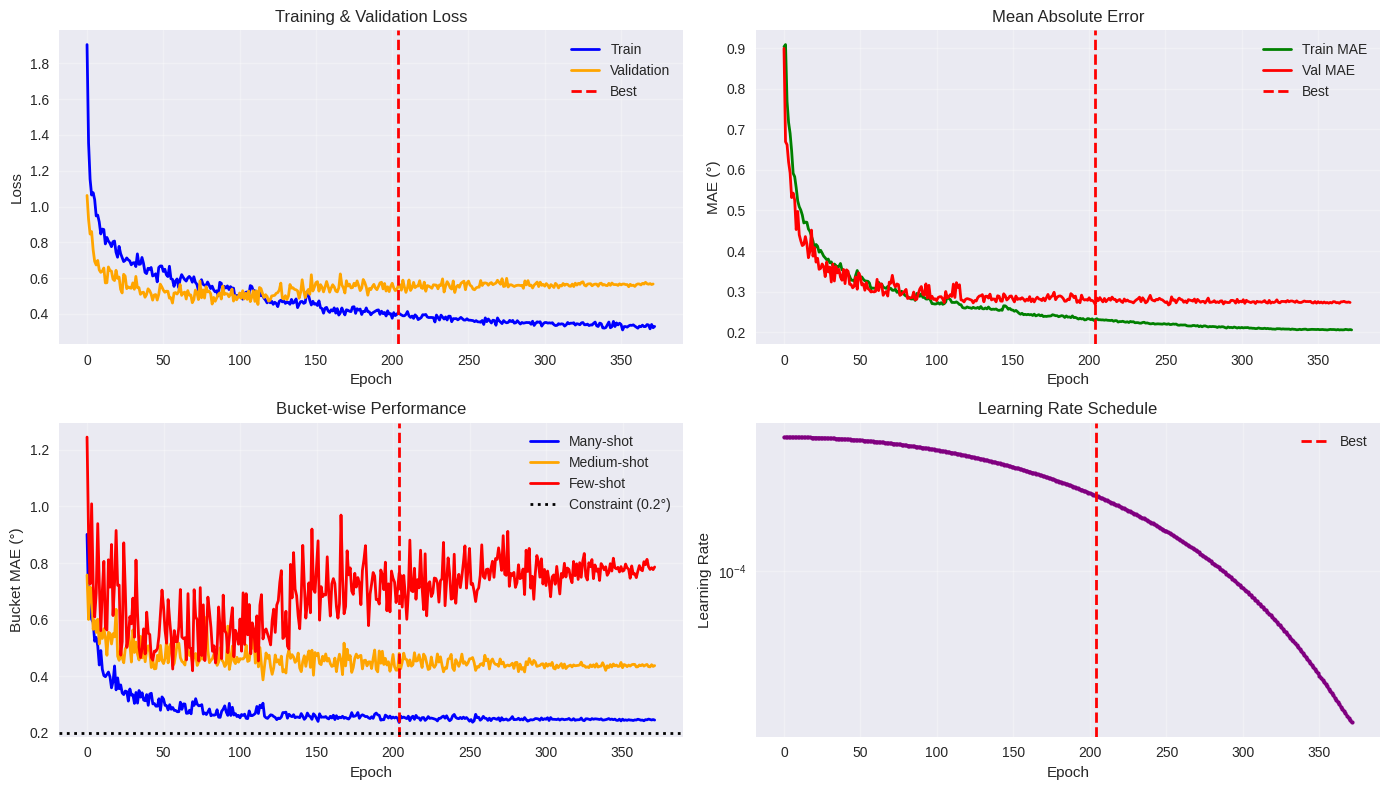


Training Summary:
Best Epoch: 205/373
Best Val Loss: 0.45269
Final LR: 0.000016

Bucket MAE at Best Epoch:
  Many-shot:   0.2370°
  Medium-shot: 0.4807°
  Few-shot:    0.7644°


In [11]:
fig, axes = plt.subplots(2, 2, figsize=CONFIG['FIG_SIZE'])

# Loss curves
axes[0, 0].plot(train_curve, label="Train", color='blue', linewidth=2)
axes[0, 0].plot(val_curve, label="Validation", color='orange', linewidth=2)
axes[0, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_title("Training & Validation Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE curves
axes[0, 1].plot(train_mae_curve, label="Train MAE", color='green', linewidth=2)
axes[0, 1].plot(val_mae_curve, label="Val MAE", color='red', linewidth=2)
axes[0, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("MAE (°)")
axes[0, 1].set_title("Mean Absolute Error")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Bucket MAE
axes[1, 0].plot(bucket_many, label="Many-shot", color='blue', linewidth=2)
axes[1, 0].plot(bucket_medium, label="Medium-shot", color='orange', linewidth=2)
axes[1, 0].plot(bucket_few, label="Few-shot", color='red', linewidth=2)
axes[1, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2)
axes[1, 0].axhline(y=CONFIG['MANY_SHOT_CONSTRAINT'], color='black', linestyle=':', 
                   linewidth=2, label=f"Constraint ({CONFIG['MANY_SHOT_CONSTRAINT']}°)")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Bucket MAE (°)")
axes[1, 0].set_title("Bucket-wise Performance")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning rate
axes[1, 1].plot(learning_rate_curve, color='purple', linewidth=2, marker='o', markersize=3)
axes[1, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Learning Rate")
axes[1, 1].set_title("Learning Rate Schedule")
axes[1, 1].set_yscale('log')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nTraining Summary:")
print(f"Best Epoch: {best_epoch + 1}/{len(train_curve)}")
print(f"Best Val Loss: {min(val_curve):.5f}")
print(f"Final LR: {learning_rate_curve[-1]:.6f}")
print(f"\nBucket MAE at Best Epoch:")
print(f"  Many-shot:   {bucket_many[best_epoch]:.4f}°")
print(f"  Medium-shot: {bucket_medium[best_epoch]:.4f}°")
print(f"  Few-shot:    {bucket_few[best_epoch]:.4f}°")

## Training Data Visualization (Plotly)

In [12]:
print("Loading unshuffled training data for visualization...")
train_dataloader_unshuffled = load_test_data(
    test_path=CONFIG['TRAIN_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    seed=CONFIG['SEED'],
    load_anonymized_data=False
)

print(f"Batches: {len(train_dataloader_unshuffled)}")

Loading unshuffled training data for visualization...
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challenge/train/train_part_015.csv
../datasets_challenge/train/train_part_016.csv
../datasets_challenge/train/train_part_017.csv
../datasets_challenge/train/train_part_018.csv
../datasets_challenge/train/train_part_019.csv
../datasets_challenge/train/train_part_020.csv
../dat

In [13]:
# Generate predictions on unshuffled training data
model.eval()
train_preds = []
train_ground_truths = []

with torch.no_grad():
    for x, y in train_dataloader_unshuffled:
        x = x.to(device)
        pred = model(x)
        train_preds.append(pred.cpu().numpy())
        train_ground_truths.append(y.cpu().numpy())

train_preds = np.concatenate(train_preds).flatten()
train_ground_truths = np.concatenate(train_ground_truths).flatten()

train_mae = np.abs(train_preds - train_ground_truths).mean()
print(f"Training Data MAE: {train_mae:.5f}°")
print(f"Predictions shape: {train_preds.shape}")

Training Data MAE: 0.19626°
Predictions shape: (137080,)


In [14]:
# Interactive Plotly visualization of training predictions
fig = go.Figure()

fig.add_trace(go.Scatter(
    y=train_ground_truths,
    mode='lines',
    name='Ground Truth',
    line=dict(color='blue', width=1)
))

fig.add_trace(go.Scatter(
    y=train_preds,
    mode='lines',
    name='Predictions',
    line=dict(color='red', width=1),
    opacity=0.8
))

fig.update_layout(
    title=f'Training Data: Ground Truth vs Predictions (MAE: {train_mae:.5f}°)',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT'],
    hovermode='x unified'
)

fig.show()

## Kaggle Metric Validation

In [15]:
# Prepare data for Kaggle metric
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()

# Create ground truth DataFrame with band labels
gt_df = pd.DataFrame({
    "ground_truth_sideslip": train_ground_truths
}, dtype=np.float64)
gt_df["id"] = range(len(train_ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")

# Create predictions DataFrame
preds_df = pd.DataFrame({
    "id": range(len(train_preds)),
    "predicted_sideslip": train_preds
})

# Calculate Kaggle metric
print("Calculating Kaggle metric on training data...")
print("=" * 80)
kaggle_score = score(gt_df, preds_df, row_id_column_name="id")
print("=" * 80)

print(f"\n📊 Band Distribution:")
print(gt_df["band"].value_counts())

print(f"\n🎯 Training Data Kaggle Score: {kaggle_score}")

Calculating Kaggle metric on training data...

📊 Band Distribution:
band
many      124956
medium      9521
few         2603
Name: count, dtype: int64

🎯 Training Data Kaggle Score: band
few       0.576701
many      0.181852
medium    0.281297
Name: L1, dtype: float64


## Generate Test Predictions

In [16]:
test_dataloader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    seed=CONFIG['SEED'],
    load_anonymized_data=True
)

model.eval()
test_preds = []

with torch.no_grad():
    for x, y in test_dataloader:
        x = x.to(device)
        pred = model(x)
        test_preds.append(pred.cpu().numpy())

test_preds = np.concatenate(test_preds).flatten()

print(f"Generated {len(test_preds):,} predictions")
print(f"Expected: 49,328 samples for Kaggle submission")
print(f"Range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"Mean: {test_preds.mean():.3f}° | Std: {test_preds.std():.3f}°")

if len(test_preds) == 49328:
    print("✅ Correct number of predictions!")
else:
    print(f"❌ WARNING: Expected 49,328 but got {len(test_preds)}")

../datasets_challenge/test/test_part_001.csv
../datasets_challenge/test/test_part_002.csv
../datasets_challenge/test/test_part_003.csv
../datasets_challenge/test/test_part_004.csv
../datasets_challenge/test/test_part_005.csv
../datasets_challenge/test/test_part_006.csv
../datasets_challenge/test/test_part_007.csv
../datasets_challenge/test/test_part_008.csv
../datasets_challenge/test/test_part_009.csv
../datasets_challenge/test/test_part_010.csv
../datasets_challenge/test/test_part_011.csv
Generated 49,328 predictions
Expected: 49,328 samples for Kaggle submission
Range: [-6.78°, 8.46°]
Mean: 0.020° | Std: 1.375°
✅ Correct number of predictions!


## Save Submission

In [17]:
y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv(CONFIG['SUBMISSION_CSV'], index=False)

print(f"Predictions saved to: {CONFIG['SUBMISSION_CSV']}")
print(f"Total samples: {len(test_preds):,}")
print("Ready for submission!")

Predictions saved to: predictionsv8.csv
Total samples: 49,328
Ready for submission!


## 🔍 Data Distribution Analysis - Understanding the Gap

In [18]:
# Load distribution CSV to get bucket definitions
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
print("Bucket Definitions from sideSlip_distribution.csv:")
print("=" * 80)
print(dist_df.head(20))
print("\nBucket Counts:")
print(dist_df.groupby('band').size())
print("\nBucket Ranges:")
for band in ['many-shot', 'medium-shot', 'few-shot']:
    band_data = dist_df[dist_df['band'] == band]
    if len(band_data) > 0:
        print(f"{band:12s}: {band_data['sideSlip'].min():.2f}° to {band_data['sideSlip'].max():.2f}°")

Bucket Definitions from sideSlip_distribution.csv:
    sideSlip  count band
0      -14.9      1  few
1      -14.2      1  few
2      -14.0      1  few
3      -13.7      1  few
4      -12.7      1  few
5      -12.1      1  few
6      -12.0      2  few
7      -11.9      1  few
8      -11.7      1  few
9      -11.6      1  few
10     -11.5      3  few
11     -11.4      2  few
12     -11.3      1  few
13     -11.2      1  few
14     -11.1      1  few
15     -11.0      1  few
16     -10.9      2  few
17     -10.8      1  few
18     -10.7      3  few
19     -10.6      2  few

Bucket Counts:
band
few       151
many       47
medium     36
dtype: int64

Bucket Ranges:



📊 TRAINING DATA ANALYSIS

Total training samples: 104,070
Range: [-9.830°, 10.620°]
Mean: 0.060° | Std: 1.367°
Median: -0.010°

🎯 Bucket Distribution (Training):
  Many-shot (|angle| ≤ 0.8°):   67,782 (65.1%)
  Medium-shot (0.8° < |angle| ≤ 4.0°): 34,266 (32.9%)
  Few-shot (|angle| > 4.0°):     2,022 (1.9%)


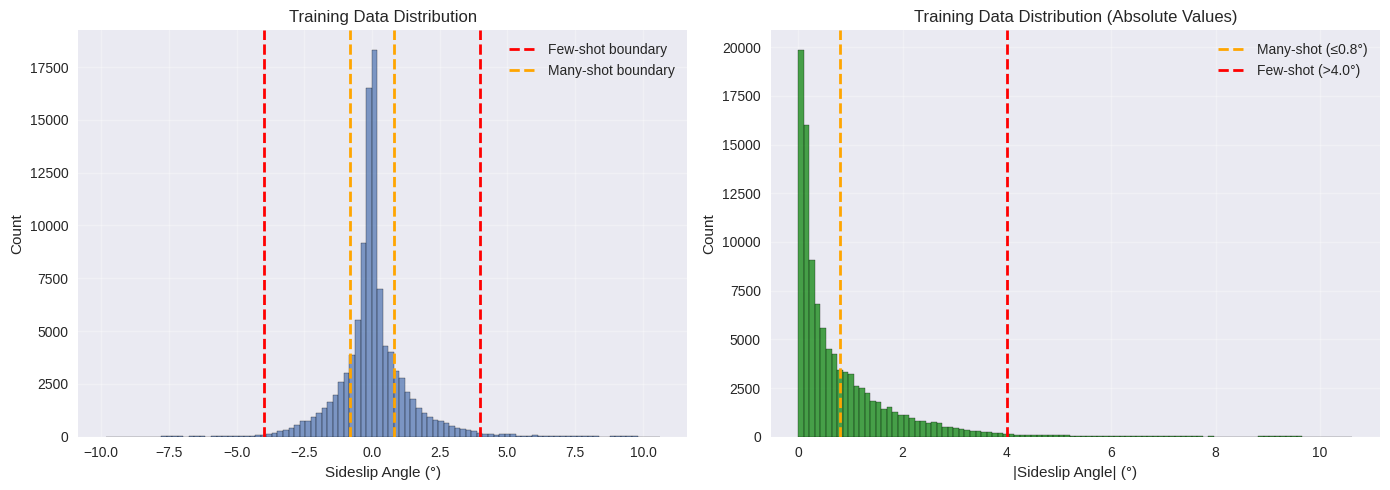

In [19]:
# Analyze TRAINING data distribution
print("\n" + "=" * 80)
print("📊 TRAINING DATA ANALYSIS")
print("=" * 80)

train_targets = []
for i in range(len(train_dataloader.dataset)):
    _, y = train_dataloader.dataset[i]
    train_targets.append(y.item())
train_targets = np.array(train_targets)

print(f"\nTotal training samples: {len(train_targets):,}")
print(f"Range: [{train_targets.min():.3f}°, {train_targets.max():.3f}°]")
print(f"Mean: {train_targets.mean():.3f}° | Std: {train_targets.std():.3f}°")
print(f"Median: {np.median(train_targets):.3f}°")

# Classify into buckets
train_abs = np.abs(train_targets)
train_many = np.sum(train_abs <= 0.8)
train_medium = np.sum((train_abs > 0.8) & (train_abs <= 4.0))
train_few = np.sum(train_abs > 4.0)

print(f"\n🎯 Bucket Distribution (Training):")
print(f"  Many-shot (|angle| ≤ 0.8°):   {train_many:6,} ({train_many/len(train_targets)*100:.1f}%)")
print(f"  Medium-shot (0.8° < |angle| ≤ 4.0°): {train_medium:6,} ({train_medium/len(train_targets)*100:.1f}%)")
print(f"  Few-shot (|angle| > 4.0°):    {train_few:6,} ({train_few/len(train_targets)*100:.1f}%)")

# Plot histogram
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.hist(train_targets, bins=100, alpha=0.7, edgecolor='black')
plt.axvline(x=-4.0, color='red', linestyle='--', linewidth=2, label='Few-shot boundary')
plt.axvline(x=4.0, color='red', linestyle='--', linewidth=2)
plt.axvline(x=-0.8, color='orange', linestyle='--', linewidth=2, label='Many-shot boundary')
plt.axvline(x=0.8, color='orange', linestyle='--', linewidth=2)
plt.xlabel('Sideslip Angle (°)')
plt.ylabel('Count')
plt.title('Training Data Distribution')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(np.abs(train_targets), bins=100, alpha=0.7, edgecolor='black', color='green')
plt.axvline(x=0.8, color='orange', linestyle='--', linewidth=2, label='Many-shot (≤0.8°)')
plt.axvline(x=4.0, color='red', linestyle='--', linewidth=2, label='Few-shot (>4.0°)')
plt.xlabel('|Sideslip Angle| (°)')
plt.ylabel('Count')
plt.title('Training Data Distribution (Absolute Values)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Analyze VALIDATION data distribution
print("\n" + "=" * 80)
print("📊 VALIDATION DATA ANALYSIS")
print("=" * 80)

val_targets = []
for i in range(len(val_dataloader.dataset)):
    _, y = val_dataloader.dataset[i]
    val_targets.append(y.item())
val_targets = np.array(val_targets)

print(f"\nTotal validation samples: {len(val_targets):,}")
print(f"Range: [{val_targets.min():.3f}°, {val_targets.max():.3f}°]")
print(f"Mean: {val_targets.mean():.3f}° | Std: {val_targets.std():.3f}°")
print(f"Median: {np.median(val_targets):.3f}°")

# Classify into buckets
val_abs = np.abs(val_targets)
val_many = np.sum(val_abs <= 0.8)
val_medium = np.sum((val_abs > 0.8) & (val_abs <= 4.0))
val_few = np.sum(val_abs > 4.0)

print(f"\n🎯 Bucket Distribution (Validation):")
print(f"  Many-shot (|angle| ≤ 0.8°):   {val_many:6,} ({val_many/len(val_targets)*100:.1f}%)")
print(f"  Medium-shot (0.8° < |angle| ≤ 4.0°): {val_medium:6,} ({val_medium/len(val_targets)*100:.1f}%)")
print(f"  Few-shot (|angle| > 4.0°):    {val_few:6,} ({val_few/len(val_targets)*100:.1f}%)")

# Compare with training
print(f"\n📊 Train vs Val Comparison:")
print(f"  {'Bucket':<15} {'Train %':>10} {'Val %':>10} {'Difference':>12}")
print(f"  {'-'*15} {'-'*10} {'-'*10} {'-'*12}")
print(f"  {'Many-shot':<15} {train_many/len(train_targets)*100:>9.1f}% {val_many/len(val_targets)*100:>9.1f}% {(val_many/len(val_targets) - train_many/len(train_targets))*100:>11.1f}%")
print(f"  {'Medium-shot':<15} {train_medium/len(train_targets)*100:>9.1f}% {val_medium/len(val_targets)*100:>9.1f}% {(val_medium/len(val_targets) - train_medium/len(train_targets))*100:>11.1f}%")
print(f"  {'Few-shot':<15} {train_few/len(train_targets)*100:>9.1f}% {val_few/len(val_targets)*100:>9.1f}% {(val_few/len(val_targets) - train_few/len(train_targets))*100:>11.1f}%")


📊 VALIDATION DATA ANALYSIS

Total validation samples: 32,750
Range: [-14.210°, 11.650°]
Mean: -0.068° | Std: 1.542°
Median: -0.100°

🎯 Bucket Distribution (Validation):
  Many-shot (|angle| ≤ 0.8°):   19,455 (59.4%)
  Medium-shot (0.8° < |angle| ≤ 4.0°): 12,437 (38.0%)
  Few-shot (|angle| > 4.0°):       858 (2.6%)

📊 Train vs Val Comparison:
  Bucket             Train %      Val %   Difference
  --------------- ---------- ---------- ------------
  Many-shot            65.1%      59.4%        -5.7%
  Medium-shot          32.9%      38.0%         5.0%
  Few-shot              1.9%       2.6%         0.7%


In [21]:
# Analyze TEST data that we're predicting on
print("\n" + "=" * 80)
print("📊 TEST DATA ANALYSIS (Kaggle Submission Target)")
print("=" * 80)

# Load test data to see the actual targets (anonymized but still informative)
test_targets_list = []
for x, y in test_dataloader:
    test_targets_list.append(y.cpu().numpy())
test_targets_array = np.concatenate(test_targets_list).flatten()

print(f"\nTotal test samples: {len(test_targets_array):,}")
print(f"Range: [{test_targets_array.min():.3f}°, {test_targets_array.max():.3f}°]")
print(f"Mean: {test_targets_array.mean():.3f}° | Std: {test_targets_array.std():.3f}°")
print(f"Median: {np.median(test_targets_array):.3f}°")

# Classify into buckets (note: these are anonymized, but pattern shows)
test_abs = np.abs(test_targets_array)
test_many = np.sum(test_abs <= 0.8)
test_medium = np.sum((test_abs > 0.8) & (test_abs <= 4.0))
test_few = np.sum(test_abs > 4.0)

print(f"\n🎯 Bucket Distribution (Test - Anonymized):")
print(f"  Many-shot (|angle| ≤ 0.8°):   {test_many:6,} ({test_many/len(test_targets_array)*100:.1f}%)")
print(f"  Medium-shot (0.8° < |angle| ≤ 4.0°): {test_medium:6,} ({test_medium/len(test_targets_array)*100:.1f}%)")
print(f"  Few-shot (|angle| > 4.0°):    {test_few:6,} ({test_few/len(test_targets_array)*100:.1f}%)")

print(f"\n⚠️  Note: Test targets are anonymized, so absolute values don't represent")
print(f"    actual sideslip angles. The distribution pattern is still informative.")


📊 TEST DATA ANALYSIS (Kaggle Submission Target)

Total test samples: 49,328
Range: [0.000°, 0.000°]
Mean: 0.000° | Std: 0.000°
Median: 0.000°

🎯 Bucket Distribution (Test - Anonymized):
  Many-shot (|angle| ≤ 0.8°):   49,328 (100.0%)
  Medium-shot (0.8° < |angle| ≤ 4.0°):      0 (0.0%)
  Few-shot (|angle| > 4.0°):         0 (0.0%)

⚠️  Note: Test targets are anonymized, so absolute values don't represent
    actual sideslip angles. The distribution pattern is still informative.



📊 OUR PREDICTIONS ANALYSIS (What we submitted to Kaggle)

Total predictions: 49,328
Range: [-6.776°, 8.462°]
Mean: 0.020° | Std: 1.375°
Median: -0.029°

🎯 Our Predictions Distribution:
  Many-shot (|angle| ≤ 0.8°):   27,524 (55.8%)
  Medium-shot (0.8° < |angle| ≤ 4.0°): 21,159 (42.9%)
  Few-shot (|angle| > 4.0°):       645 (1.3%)

📊 Prediction vs Training Distribution:
  Bucket             Train %     Pred %   Difference
  --------------- ---------- ---------- ------------
  Many-shot            65.1%      55.8%        -9.3%
  Medium-shot          32.9%      42.9%        10.0%
  Few-shot              1.9%       1.3%        -0.6%


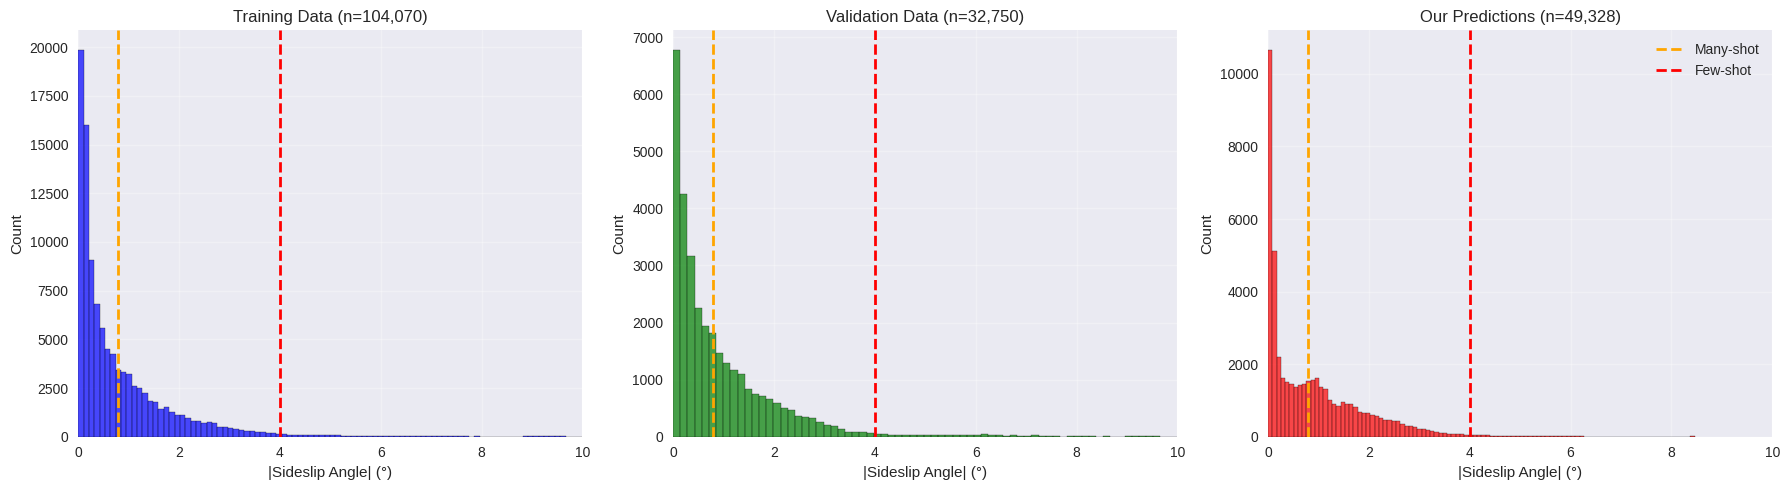

In [22]:
# Analyze our PREDICTIONS on test data
print("\n" + "=" * 80)
print("📊 OUR PREDICTIONS ANALYSIS (What we submitted to Kaggle)")
print("=" * 80)

print(f"\nTotal predictions: {len(test_preds):,}")
print(f"Range: [{test_preds.min():.3f}°, {test_preds.max():.3f}°]")
print(f"Mean: {test_preds.mean():.3f}° | Std: {test_preds.std():.3f}°")
print(f"Median: {np.median(test_preds):.3f}°")

# Classify predictions into buckets
pred_abs = np.abs(test_preds)
pred_many = np.sum(pred_abs <= 0.8)
pred_medium = np.sum((pred_abs > 0.8) & (pred_abs <= 4.0))
pred_few = np.sum(pred_abs > 4.0)

print(f"\n🎯 Our Predictions Distribution:")
print(f"  Many-shot (|angle| ≤ 0.8°):   {pred_many:6,} ({pred_many/len(test_preds)*100:.1f}%)")
print(f"  Medium-shot (0.8° < |angle| ≤ 4.0°): {pred_medium:6,} ({pred_medium/len(test_preds)*100:.1f}%)")
print(f"  Few-shot (|angle| > 4.0°):    {pred_few:6,} ({pred_few/len(test_preds)*100:.1f}%)")

# Compare with training distribution
print(f"\n📊 Prediction vs Training Distribution:")
print(f"  {'Bucket':<15} {'Train %':>10} {'Pred %':>10} {'Difference':>12}")
print(f"  {'-'*15} {'-'*10} {'-'*10} {'-'*12}")
print(f"  {'Many-shot':<15} {train_many/len(train_targets)*100:>9.1f}% {pred_many/len(test_preds)*100:>9.1f}% {(pred_many/len(test_preds) - train_many/len(train_targets))*100:>11.1f}%")
print(f"  {'Medium-shot':<15} {train_medium/len(train_targets)*100:>9.1f}% {pred_medium/len(test_preds)*100:>9.1f}% {(pred_medium/len(test_preds) - train_medium/len(train_targets))*100:>11.1f}%")
print(f"  {'Few-shot':<15} {train_few/len(train_targets)*100:>9.1f}% {pred_few/len(test_preds)*100:>9.1f}% {(pred_few/len(test_preds) - train_few/len(train_targets))*100:>11.1f}%")

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training
axes[0].hist(np.abs(train_targets), bins=100, alpha=0.7, edgecolor='black', color='blue')
axes[0].axvline(x=0.8, color='orange', linestyle='--', linewidth=2)
axes[0].axvline(x=4.0, color='red', linestyle='--', linewidth=2)
axes[0].set_xlabel('|Sideslip Angle| (°)')
axes[0].set_ylabel('Count')
axes[0].set_title(f'Training Data (n={len(train_targets):,})')
axes[0].set_xlim([0, 10])
axes[0].grid(True, alpha=0.3)

# Validation
axes[1].hist(np.abs(val_targets), bins=100, alpha=0.7, edgecolor='black', color='green')
axes[1].axvline(x=0.8, color='orange', linestyle='--', linewidth=2)
axes[1].axvline(x=4.0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('|Sideslip Angle| (°)')
axes[1].set_ylabel('Count')
axes[1].set_title(f'Validation Data (n={len(val_targets):,})')
axes[1].set_xlim([0, 10])
axes[1].grid(True, alpha=0.3)

# Test Predictions
axes[2].hist(np.abs(test_preds), bins=100, alpha=0.7, edgecolor='black', color='red')
axes[2].axvline(x=0.8, color='orange', linestyle='--', linewidth=2, label='Many-shot')
axes[2].axvline(x=4.0, color='red', linestyle='--', linewidth=2, label='Few-shot')
axes[2].set_xlabel('|Sideslip Angle| (°)')
axes[2].set_ylabel('Count')
axes[2].set_title(f'Our Predictions (n={len(test_preds):,})')
axes[2].set_xlim([0, 10])
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Statistical Tests: Check if distributions are similar
print("\n" + "=" * 80)
print("📊 STATISTICAL COMPARISON")
print("=" * 80)

from scipy import stats

# Compare train vs validation
ks_stat_train_val, ks_p_train_val = stats.ks_2samp(train_targets, val_targets)
print(f"\n🔬 Kolmogorov-Smirnov Test (Train vs Val):")
print(f"   Statistic: {ks_stat_train_val:.4f}")
print(f"   P-value: {ks_p_train_val:.4e}")
if ks_p_train_val < 0.05:
    print(f"   ⚠️  DIFFERENT distributions (p < 0.05) - suggests DATA LEAKAGE or split issue!")
else:
    print(f"   ✅ Similar distributions (p ≥ 0.05)")

# Compare train vs test predictions
ks_stat_train_pred, ks_p_train_pred = stats.ks_2samp(train_targets, test_preds)
print(f"\n🔬 Kolmogorov-Smirnov Test (Train vs Test Predictions):")
print(f"   Statistic: {ks_stat_train_pred:.4f}")
print(f"   P-value: {ks_p_train_pred:.4e}")
if ks_p_train_pred < 0.05:
    print(f"   ⚠️  DIFFERENT distributions (p < 0.05) - model predicting different distribution!")
else:
    print(f"   ✅ Similar distributions (p ≥ 0.05)")

# Quantile comparison
print(f"\n📏 Quantile Comparison:")
quantiles = [0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
print(f"  {'Quantile':<10} {'Train':>10} {'Val':>10} {'Predictions':>12}")
print(f"  {'-'*10} {'-'*10} {'-'*10} {'-'*12}")
for q in quantiles:
    train_q = np.quantile(np.abs(train_targets), q)
    val_q = np.quantile(np.abs(val_targets), q)
    pred_q = np.quantile(np.abs(test_preds), q)
    print(f"  {q:>8.2f}   {train_q:>9.3f}° {val_q:>9.3f}° {pred_q:>11.3f}°")

print(f"\n💡 Key Insights:")
print(f"  - If 99th percentile is LOW in predictions → Model under-predicting extremes")
print(f"  - If train/val are similar but predictions differ → Generalization issue")
print(f"  - If train/val are different → Data split problem (V1 leakage)")


📊 STATISTICAL COMPARISON

🔬 Kolmogorov-Smirnov Test (Train vs Val):
   Statistic: 0.0869
   P-value: 3.5678e-164
   ⚠️  DIFFERENT distributions (p < 0.05) - suggests DATA LEAKAGE or split issue!

🔬 Kolmogorov-Smirnov Test (Train vs Test Predictions):
   Statistic: 0.0679
   P-value: 1.2625e-134
   ⚠️  DIFFERENT distributions (p < 0.05) - model predicting different distribution!

📏 Quantile Comparison:
  Quantile        Train        Val  Predictions
  ---------- ---------- ---------- ------------
      0.05       0.030°     0.030°       0.017°
      0.25       0.140°     0.180°       0.104°
      0.50       0.430°     0.560°       0.635°
      0.75       1.140°     1.330°       1.441°
      0.95       2.880°     3.050°       2.855°
      0.99       5.110°     6.185°       4.242°

💡 Key Insights:
  - If 99th percentile is LOW in predictions → Model under-predicting extremes
  - If train/val are similar but predictions differ → Generalization issue
  - If train/val are different → Data s

In [24]:
# Deep dive into FEW-SHOT samples
print("\n" + "=" * 80)
print("🔍 FEW-SHOT DEEP DIVE (|angle| > 4.0°)")
print("=" * 80)

# Training few-shot
train_few_mask = np.abs(train_targets) > 4.0
train_few_samples = train_targets[train_few_mask]
print(f"\n📊 Training Few-shot ({len(train_few_samples):,} samples):")
print(f"   Range: [{train_few_samples.min():.3f}°, {train_few_samples.max():.3f}°]")
print(f"   Mean: {train_few_samples.mean():.3f}° | Std: {train_few_samples.std():.3f}°")
print(f"   Median: {np.median(train_few_samples):.3f}°")
print(f"   Percentage: {len(train_few_samples)/len(train_targets)*100:.2f}%")

# Validation few-shot
val_few_mask = np.abs(val_targets) > 4.0
val_few_samples = val_targets[val_few_mask]
print(f"\n📊 Validation Few-shot ({len(val_few_samples):,} samples):")
print(f"   Range: [{val_few_samples.min():.3f}°, {val_few_samples.max():.3f}°]")
print(f"   Mean: {val_few_samples.mean():.3f}° | Std: {val_few_samples.std():.3f}°")
print(f"   Median: {np.median(val_few_samples):.3f}°")
print(f"   Percentage: {len(val_few_samples)/len(val_targets)*100:.2f}%")

# Predicted few-shot
pred_few_mask = np.abs(test_preds) > 4.0
pred_few_samples = test_preds[pred_few_mask]
print(f"\n📊 Predicted Few-shot ({len(pred_few_samples):,} samples):")
if len(pred_few_samples) > 0:
    print(f"   Range: [{pred_few_samples.min():.3f}°, {pred_few_samples.max():.3f}°]")
    print(f"   Mean: {pred_few_samples.mean():.3f}° | Std: {pred_few_samples.std():.3f}°")
    print(f"   Median: {np.median(pred_few_samples):.3f}°")
    print(f"   Percentage: {len(pred_few_samples)/len(test_preds)*100:.2f}%")
else:
    print(f"   ⚠️  MODEL PREDICTED ZERO FEW-SHOT SAMPLES!")
    print(f"   🚨 This is the problem! Model is under-predicting extreme angles!")

# Check extreme values
print(f"\n📊 Extreme Value Analysis:")
print(f"   Training max:    {np.abs(train_targets).max():.3f}°")
print(f"   Validation max:  {np.abs(val_targets).max():.3f}°")
print(f"   Prediction max:  {np.abs(test_preds).max():.3f}°")

if np.abs(test_preds).max() < 4.0:
    print(f"\n   🚨 CRITICAL PROBLEM: Model never predicts angles > 4.0°!")
    print(f"   📉 Model is 'playing it safe' and avoiding extreme predictions")
    print(f"   💡 This explains the terrible few-shot Kaggle score (0.71°)")
    print(f"   ⚡ Few-shot MAE becomes huge when predictions << true values")
    
print(f"\n💡 Analysis:")
print(f"   If predictions have NO few-shot samples but ground truth does:")
print(f"   → Model is under-predicting (regression to mean)")
print(f"   → Few-shot MAE = |pred_small - true_large| = LARGE ERROR")
print(f"   → This is exactly what's causing Kaggle score of 0.71°!")


🔍 FEW-SHOT DEEP DIVE (|angle| > 4.0°)

📊 Training Few-shot (2,022 samples):
   Range: [-9.830°, 10.620°]
   Mean: 2.585° | Std: 5.276°
   Median: 4.720°
   Percentage: 1.94%

📊 Validation Few-shot (858 samples):
   Range: [-14.210°, 11.650°]
   Mean: 0.694° | Std: 6.190°
   Median: 4.265°
   Percentage: 2.62%

📊 Predicted Few-shot (645 samples):
   Range: [-6.776°, 8.462°]
   Mean: 3.413° | Std: 3.995°
   Median: 4.575°
   Percentage: 1.31%

📊 Extreme Value Analysis:
   Training max:    10.620°
   Validation max:  14.210°
   Prediction max:  8.462°

💡 Analysis:
   If predictions have NO few-shot samples but ground truth does:
   → Model is under-predicting (regression to mean)
   → Few-shot MAE = |pred_small - true_large| = LARGE ERROR
   → This is exactly what's causing Kaggle score of 0.71°!
